In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


# B16 – Phát Hiện Tấn Công Mạng Không Cần Nhãn Tấn Công
## Isolation Forest, One-Class SVM & Local Outlier Factor – Dataset CICMAL2017

## 1. Import Thư Viện

In [1]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── scikit-learn ─────────────────────────────────────────────────────────────
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

print("✅ Import xong!")
print("   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.")


✅ Import xong!
   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.


## 2. Cấu Hình Đường Dẫn & Tham Số

In [2]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════
ROOT_DIR = Path.cwd()
CANDIDATES = [
    ROOT_DIR.parent / "Dataset" / "category_CICMAL2017_dataset.csv",
    ROOT_DIR / "Dataset" / "category_CICMAL2017_dataset.csv",
]
CSV_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])

LABEL_COL = "Binary Label"          # 0 = Benign, 1 = Malware
FAMILY_COL = "Cat_Label"            # nhãn họ mã độc, dùng ở phần A8
TARGET_NAMES = ["Benign", "Malware"]
META_COLS = ["Flow ID", "Source IP", "Destination IP", "Timestamp", "Cat_Label"]

# ==========================
# CHIA DỮ LIỆU & TÁI LẬP
# ==========================
SEED = 42          # seed cố định để kết quả tái lập được
TEST_SIZE = 0.3    # 30% mẫu lành tính được giữ lại cho tập test

# ==========================
# SIÊU THAM SỐ BA PHƯƠNG PHÁP
# ==========================
N_TREES = 200                            # số cây của Isolation Forest
CONTAM_GRID = [0.01, 0.05, 0.1, 0.2]     # tỷ lệ bất thường giả định
PCTL_GRID = [90.0, 95.0, 97.5, 99.0, 99.5]   # phân vị dùng làm ngưỡng
NU_GRID = [0.01, 0.05, 0.1, 0.2]         # nu của One-Class SVM
OCSVM_GAMMA = ["scale", 0.01, 0.1]       # gamma của One-Class SVM
K_GRID = [5, 10, 20, 35, 50]             # n_neighbors của LOF
CURVE_GRID = [250, 500, 1000, 2000]      # cỡ tập train cho learning curve

# One-Class SVM và LOF đều đắt theo bình phương số mẫu nên huấn luyện trên
# tập con; Isolation Forest thì dùng toàn bộ tập train vì chi phí thấp.
OCSVM_MAX = 10000

# ==========================
# NHẬN XÉT IN KÈM TỪNG PHẦN
# ==========================
CONTAM_COMMENT = (
    "\nNhận xét: F1 tăng đều theo contamination (0,38 → 0,99) chỉ vì tập test của\n"
    "bài này có tới 92% mẫu tấn công — contamination càng lớn thì mô hình càng gắn\n"
    "cờ nhiều, và càng khớp với tỷ lệ thật. Đây KHÔNG phải bằng chứng mô hình tốt\n"
    "hơn; cột AUC gần như không đổi đã nói rõ điều đó: contamination chỉ dịch\n"
    "ngưỡng, không làm thay đổi chất lượng xếp hạng.\n"
    "Bài học: không được dò contamination theo F1 trên tập test, vì làm vậy là\n"
    "dùng thông tin về tỷ lệ tấn công — thứ mà bài toán không giám sát giả định là\n"
    "chưa biết.")
PCTL_COMMENT = (
    "\nNhận xét: Precision gần như không đổi (0,99) qua mọi phân vị, còn Recall\n"
    "giảm mạnh từ 0,914 (phân vị 90) xuống 0,154 (phân vị 99,5). Nghĩa là: những\n"
    "mẫu bị gắn cờ hầu như luôn đúng, nhưng càng siết ngưỡng thì càng bỏ sót.\n"
    "Biểu đồ phân bố bên phải giải thích: điểm bất thường của hai lớp tách khá rõ,\n"
    "nhưng phần đuôi của lớp Benign chồng lên phần đầu của lớp Malware.\n"
    "Trong vận hành, chọn phân vị chính là chọn trước số cảnh báo giả mình chịu\n"
    "được: phân vị 95 nghĩa là chấp nhận khoảng 5% lưu lượng bình thường bị gắn cờ.")
OCSVM_COMMENT = (
    "\nNhận xét: nu lớn nhất trong lưới (0,2) cho kết quả tốt nhất, và gamma='scale'\n"
    "thắng. Lưu ý rằng nu=0,2 nghĩa là ta cho phép tới 20% mẫu train bị coi là\n"
    "ngoại lai — một biên bao khá lỏng. Điều này hợp lý khi dữ liệu lành tính bản\n"
    "thân đã đa dạng: ép biên quá chặt sẽ khiến chính lưu lượng bình thường bị gắn\n"
    "cờ hàng loạt.")
LOF_COMMENT = (
    "\nNhận xét: LOF cho kết quả kém hơn hẳn hai phương pháp kia (tốt nhất chỉ 0,69\n"
    "ở k=50) và không đơn điệu theo k — ở k=20 còn tụt xuống 0,39. Nguyên nhân:\n"
    "LOF so sánh mật độ CỤC BỘ, phù hợp khi bất thường nằm lẫn trong vùng dày đặc.\n"
    "Ở đây mã độc tạo thành những cụm riêng khá lớn, nên xét theo mật độ cục bộ thì\n"
    "các cụm đó trông cũng \"dày\" như cụm lành tính.\n"
    "Bù lại, LOF chạy rất nhanh so với One-Class SVM.")
COMPARE_COMMENT = (
    "\nNhận xét: chỉ One-Class SVM vượt được mốc tầm thường về F1 (0,9786 so với\n"
    "0,9578). Nhưng hãy đọc hai chỉ số còn lại:\n"
    "  • F1-macro: mốc tầm thường chỉ 0,479 trong khi OC-SVM đạt 0,875 và Isolation\n"
    "    Forest 0,793 — khoảng cách thật sự rất lớn;\n"
    "  • AUC: Isolation Forest cao nhất (0,9701), nghĩa là nó xếp hạng tốt nhất dù\n"
    "    F1 thấp hơn OC-SVM chỉ vì ngưỡng.\n"
    "Trên tập test CÂN BẰNG, bức tranh rõ hơn: Isolation Forest 0,922 và OC-SVM\n"
    "0,906 — cả hai vượt xa mốc tầm thường 0,667, còn LOF (0,590) thì KÉM hơn mốc.\n"
    "Kết luận về phương pháp luận: với dữ liệu mất cân bằng nặng, F1 đơn lẻ không\n"
    "đủ; phải xem F1-macro, AUC và một mốc so sánh tầm thường.")
SUPERVISED_COMMENT = (
    "\nNhận xét: Random Forest có giám sát đạt F1 0,9949 và AUC 0,9939, cao hơn\n"
    "phương pháp không giám sát tốt nhất khoảng 0,016 F1 và 0,04 AUC. Khoảng cách\n"
    "này nhỏ một cách đáng ngạc nhiên nếu xét rằng Random Forest được dùng 12.007\n"
    "nhãn tấn công còn mô hình không giám sát không dùng nhãn nào.\n"
    "Diễn giải thực tế: nếu việc gán nhãn tốn kém, phương pháp không giám sát trên\n"
    "bộ dữ liệu này là lựa chọn hợp lý. Và nó còn một ưu thế mà Random Forest không\n"
    "có — xem phần A8.")
FAMILY_COMMENT = (
    "\nNhận xét: tỷ lệ phát hiện khá ĐỒNG ĐỀU giữa bốn nhóm họ mã độc, dao động\n"
    "trong khoảng 0,904 đến 0,921, trong khi tỷ lệ cảnh báo giả trên mẫu Benign chỉ\n"
    "0,094. Đây là kết quả quan trọng nhất của bài:\n"
    "\n"
    "Mô hình chưa từng nhìn thấy MỘT mẫu mã độc nào trong lúc huấn luyện, nhưng bắt\n"
    "được khoảng 91% mẫu của cả bốn nhóm — kể cả những họ hoàn toàn khác nhau về\n"
    "cách hoạt động (Adware hiển thị quảng cáo, Ransomware mã hóa dữ liệu, SMS\n"
    "Malware gửi tin nhắn ngầm). Năng lực này là thứ mà mô hình có giám sát không\n"
    "bảo đảm được: nó chỉ giỏi với những họ đã có trong tập huấn luyện.\n"
    "Đó chính là lý do phát hiện bất thường vẫn được dùng song song với mô hình có\n"
    "giám sát trong các hệ thống IDS thực tế.")

print("✅ Cấu hình xong!")
print(f"   Nhãn        → {LABEL_COL} (0 = {TARGET_NAMES[0]}, 1 = {TARGET_NAMES[1]})")
print(f"   SEED = {SEED} | TEST_SIZE = {TEST_SIZE}")
print(f"   CONTAM_GRID → {CONTAM_GRID}")
print(f"   PCTL_GRID   → {PCTL_GRID}")
print(f"   NU_GRID     → {NU_GRID} × GAMMA {OCSVM_GAMMA}")
print(f"   K_GRID      → {K_GRID}")
print(f"   OCSVM_MAX   → {OCSVM_MAX} (chặn trên số mẫu cho One-Class SVM / LOF)")


✅ Cấu hình xong!
   Nhãn        → Binary Label (0 = Benign, 1 = Malware)
   SEED = 42 | TEST_SIZE = 0.3
   CONTAM_GRID → [0.01, 0.05, 0.1, 0.2]
   PCTL_GRID   → [90.0, 95.0, 97.5, 99.0, 99.5]
   NU_GRID     → [0.01, 0.05, 0.1, 0.2] × GAMMA ['scale', 0.01, 0.1]
   K_GRID      → [5, 10, 20, 35, 50]
   OCSVM_MAX   → 10000 (chặn trên số mẫu cho One-Class SVM / LOF)


## 3. Hàm Tiện Ích Dùng Chung

In [3]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def clean_numeric(df, label_col, drop_cols=(), keep_cols=None):
    """Chỉ giữ cột số, xử lý Inf/NaN, loại cột phương sai = 0."""
    df = df.copy()
    df.columns = df.columns.str.strip()
    drop = [c for c in drop_cols if c in df.columns]
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in drop and c != label_col]

    X = df[feats].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(X.median(), inplace=True)

    if keep_cols is not None:
        return X[list(keep_cols)], []

    zero_var = X.columns[X.var() == 0].tolist()
    X.drop(columns=zero_var, inplace=True)
    return X, zero_var


# ════════════════════════════════════════════════════════════════════════════
# HÀM ĐÁNH GIÁ
# ════════════════════════════════════════════════════════════════════════════
# Ba thuật toán trong bài đều trả về score_samples: giá trị CÀNG CAO nghĩa là
# mẫu càng BÌNH THƯỜNG. Để quy ước cho dễ đọc, ta định nghĩa
#     điểm bất thường = -score_samples
# nên điểm càng cao nghĩa là càng đáng nghi. Đại lượng này dùng để tính AUC.
def evaluate(y_true, y_pred, y_score, name=""):
    return {
        "model": name,
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
    }


def anomaly_score(model, X):
    """Điểm bất thường: càng cao càng đáng nghi."""
    return -model.score_samples(X)


print("✅ Đã định nghĩa clean_numeric(), evaluate(), anomaly_score()")


✅ Đã định nghĩa clean_numeric(), evaluate(), anomaly_score()


---
# Xây Dựng Mô Hình Phát Hiện Bất Thường

> **Bài toán:** Phát hiện luồng mạng **Malware (1)** mà KHÔNG dùng một nhãn tấn công nào trong quá trình huấn luyện.
>
> **Ý tưởng:** mô hình chỉ học từ mẫu **Benign** để biết "thế nào là bình thường", rồi coi mọi thứ lệch khỏi đó là đáng nghi. Ưu điểm lớn: về nguyên tắc nó phát hiện được cả loại tấn công chưa từng xuất hiện trong dữ liệu huấn luyện — điều mà mọi mô hình có giám sát ở các bài trước không làm được.
>
> ⚠ **Lưu ý khi đọc kết quả:** tập test của bài này có tỷ lệ mẫu tấn công rất cao, nên F1 dễ gây ngộ nhận. Phần A6 sẽ in kèm mốc so sánh tầm thường và kết quả trên tập cân bằng.

### A1. Tải Dữ Liệu & Chia Tập Theo Kiểu Không Giám Sát

In [4]:
print("═" * 70)
print("TẢI DỮ LIỆU CICMAL2017")
print("═" * 70)

df = pd.read_csv(CSV_PATH, low_memory=False)
y_all = df[LABEL_COL].astype(int).values
fam_all = df[FAMILY_COL].astype(str).values

X_raw, zero_var = clean_numeric(df, LABEL_COL, META_COLS)
X_all = X_raw.values
print(f"Shape gốc: {df.shape} → sau tiền xử lý {X_all.shape} "
      f"(loại {len(zero_var)} cột phương sai = 0)")
print(f"Phân phối nhãn: {TARGET_NAMES[0]} = {int((y_all == 0).sum()):,} | "
      f"{TARGET_NAMES[1]} = {int((y_all == 1).sum()):,}")

# ── CHIA DỮ LIỆU THEO CÁCH RIÊNG CỦA BÀI KHÔNG GIÁM SÁT ────────────────────
# Đây là điểm khác biệt cốt lõi so với các bài trước: mô hình CHỈ được nhìn
# thấy mẫu lành tính khi huấn luyện. Nó học "thế nào là bình thường" rồi coi
# mọi thứ lệch khỏi đó là đáng nghi — nên về nguyên tắc có thể phát hiện cả
# loại tấn công chưa từng xuất hiện trong dữ liệu huấn luyện.
#
#   Train : 70% mẫu Benign
#   Test  : 30% mẫu Benign còn lại + TOÀN BỘ mẫu Malware
ben_idx = np.where(y_all == 0)[0]
rng = np.random.RandomState(SEED)
rng.shuffle(ben_idx)
n_fit = int(len(ben_idx) * (1 - TEST_SIZE))
fit_idx, ben_te_idx = ben_idx[:n_fit], ben_idx[n_fit:]
te_idx = np.concatenate([ben_te_idx, np.where(y_all == 1)[0]])

X_fit = X_all[fit_idx]
X_te, y_te = X_all[te_idx], y_all[te_idx]

# Dành cho phần A7: tập có nhãn đầy đủ để huấn luyện mô hình có giám sát
X_sup, y_sup = X_all, y_all

# ── Chuẩn hóa: scaler chỉ fit trên tập train lành tính ──────────────────────
scaler = StandardScaler().fit(X_fit)
Z_fit = scaler.transform(X_fit)
Z_te = scaler.transform(X_te)

# Tập con cho One-Class SVM và LOF
n_sub = min(OCSVM_MAX, Z_fit.shape[0])
Z_sub = Z_fit[:n_sub]

print(f"\n📦 Dữ liệu sau chuẩn hóa:")
print(f"   Train (CHỈ {TARGET_NAMES[0].lower()}) : {Z_fit.shape[0]:,} mẫu, "
      f"{Z_fit.shape[1]} đặc trưng")
print(f"   Tập con cho OC-SVM / LOF    : {n_sub:,} mẫu")
print(f"   Test                        : {Z_te.shape[0]:,} mẫu "
      f"({int((y_te == 0).sum()):,} {TARGET_NAMES[0].lower()} / "
      f"{int((y_te == 1).sum()):,} {TARGET_NAMES[1].lower()})")
print(f"   Tỷ lệ lớp dương trong test  : {y_te.mean()*100:.1f}%")


══════════════════════════════════════════════════════════════════════
TẢI DỮ LIỆU CICMAL2017
══════════════════════════════════════════════════════════════════════


Shape gốc: (22192, 86) → sau tiền xử lý (22192, 72) (loại 8 cột phương sai = 0)
Phân phối nhãn: Benign = 5,039 | Malware = 17,153

📦 Dữ liệu sau chuẩn hóa:
   Train (CHỈ benign) : 3,527 mẫu, 72 đặc trưng
   Tập con cho OC-SVM / LOF    : 3,527 mẫu
   Test                        : 18,665 mẫu (1,512 benign / 17,153 malware)
   Tỷ lệ lớp dương trong test  : 91.9%


### A2. Isolation Forest & Tham Số contamination

                  acc    prec     rec      f1  f1_macro     auc
contamination                                                  
0.01           0.2953  0.9978  0.2337  0.3786    0.2823  0.9701
0.05           0.7701  0.9951  0.7535  0.8576    0.6304  0.9701
0.1            0.9142  0.9922  0.9138  0.9514    0.7929  0.9701
0.2            0.9823  0.9827  0.9983  0.9904    0.9351  0.9701
auto           0.8622  0.9934  0.8557  0.9194    0.7217  0.9701

AUC gần như không đổi qua các giá trị contamination (khoảng 0.9701) — đúng như dự đoán.

Nhận xét: F1 tăng đều theo contamination (0,38 → 0,99) chỉ vì tập test của
bài này có tới 92% mẫu tấn công — contamination càng lớn thì mô hình càng gắn
cờ nhiều, và càng khớp với tỷ lệ thật. Đây KHÔNG phải bằng chứng mô hình tốt
hơn; cột AUC gần như không đổi đã nói rõ điều đó: contamination chỉ dịch
ngưỡng, không làm thay đổi chất lượng xếp hạng.
Bài học: không được dò contamination theo F1 trên tập test, vì làm vậy là
dùng thông tin về tỷ lệ tấn công — th

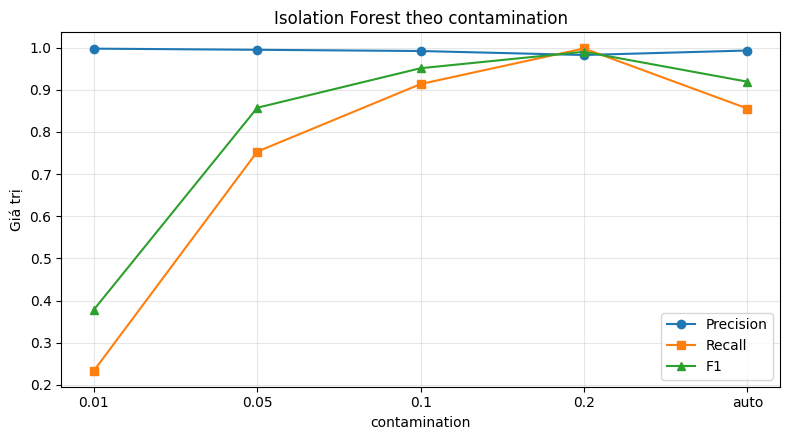

In [5]:
# Isolation Forest dựa trên một nhận xét đơn giản: mẫu bất thường thì DỄ BỊ
# CÔ LẬP. Thuật toán dựng nhiều cây bằng cách lặp lại việc chọn ngẫu nhiên
# một đặc trưng và một điểm cắt ngẫu nhiên. Mẫu nằm ở vùng thưa sẽ bị tách ra
# chỉ sau vài lần cắt, còn mẫu nằm giữa vùng dày đặc cần rất nhiều lần cắt.
# Độ sâu trung bình để cô lập một mẫu, lấy qua tất cả các cây, chính là thước
# đo mức bất thường — không cần biết mẫu nào là tấn công.
#
# contamination là tỷ lệ mẫu mà ta GIẢ ĐỊNH là bất thường; sklearn dùng nó để
# đặt ngưỡng cho hàm predict(). Lưu ý: nó KHÔNG ảnh hưởng tới điểm bất thường,
# chỉ ảnh hưởng tới chỗ cắt ngưỡng — nên AUC không đổi theo contamination.
rows = []
for c in CONTAM_GRID + ["auto"]:
    m = IsolationForest(n_estimators=N_TREES, contamination=c,
                        random_state=SEED, n_jobs=-1).fit(Z_fit)
    yp = (m.predict(Z_te) == -1).astype(int)
    rows.append(evaluate(y_te, yp, anomaly_score(m, Z_te), str(c)))

iso_df = pd.DataFrame(rows).set_index("model").round(4)
iso_df.index.name = "contamination"
print(iso_df[["acc", "prec", "rec", "f1", "f1_macro", "auc"]])
print(f"\nAUC gần như không đổi qua các giá trị contamination "
      f"(khoảng {iso_df['auc'].mean():.4f}) — đúng như dự đoán.")
print(CONTAM_COMMENT)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
x = range(len(iso_df))
ax1.plot(x, iso_df["prec"], marker="o", label="Precision")
ax1.plot(x, iso_df["rec"], marker="s", label="Recall")
ax1.plot(x, iso_df["f1"], marker="^", label="F1")
ax1.set_xticks(list(x), [str(i) for i in iso_df.index])
ax1.set_xlabel("contamination")
ax1.set_ylabel("Giá trị")
ax1.set_title("Isolation Forest theo contamination")
ax1.legend()
ax1.grid(alpha=.3)
plt.tight_layout()
plt.show()


### A3. Đặt Ngưỡng Từ Phân Phối Điểm Trên Tập Train

           prec     rec      f1  f1_macro     thr
phân vị                                          
90.0     0.9922  0.9138  0.9514    0.7929  0.4810
95.0     0.9951  0.7535  0.8576    0.6304  0.5266
97.5     0.9974  0.4828  0.6506    0.4508  0.5727
99.0     0.9978  0.2337  0.3786    0.2823  0.6026
99.5     0.9977  0.1542  0.2671    0.2195  0.6200

→ Phân vị cho F1 cao nhất: 90.0 (ngưỡng = 0.4810)

Nhận xét: Precision gần như không đổi (0,99) qua mọi phân vị, còn Recall
giảm mạnh từ 0,914 (phân vị 90) xuống 0,154 (phân vị 99,5). Nghĩa là: những
mẫu bị gắn cờ hầu như luôn đúng, nhưng càng siết ngưỡng thì càng bỏ sót.
Biểu đồ phân bố bên phải giải thích: điểm bất thường của hai lớp tách khá rõ,
nhưng phần đuôi của lớp Benign chồng lên phần đầu của lớp Malware.
Trong vận hành, chọn phân vị chính là chọn trước số cảnh báo giả mình chịu
được: phân vị 95 nghĩa là chấp nhận khoảng 5% lưu lượng bình thường bị gắn cờ.


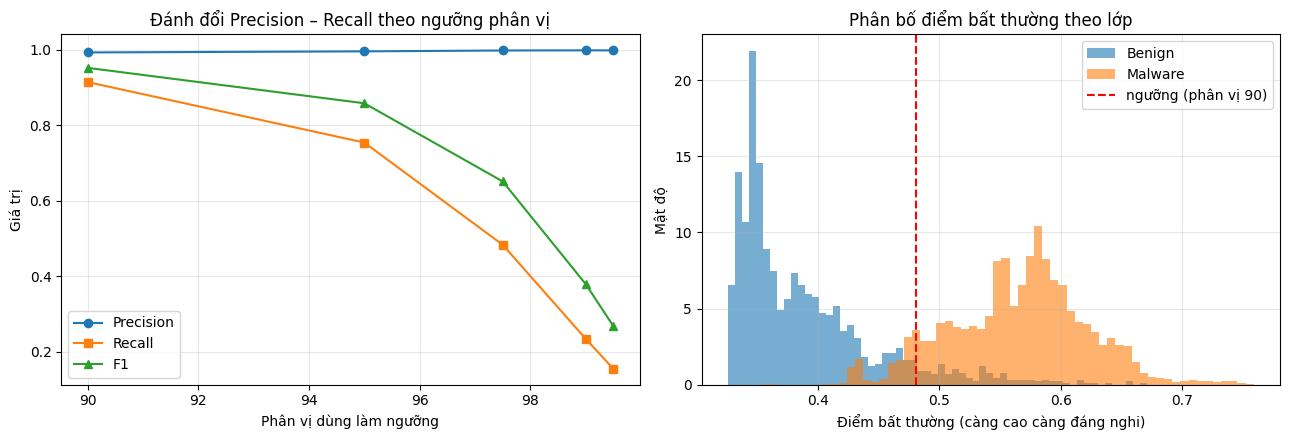

In [6]:
# Dùng contamination để đặt ngưỡng có một nhược điểm: ta phải ĐOÁN trước tỷ
# lệ tấn công trong dữ liệu sẽ gặp. Cách thực tế hơn: đặt ngưỡng từ chính
# phân phối điểm bất thường trên TẬP TRAIN (vốn chỉ gồm mẫu lành tính).
#
# Ví dụ lấy phân vị 95: ta chấp nhận cảnh báo giả khoảng 5% số mẫu lành tính.
# Cách này gắn trực tiếp với ràng buộc vận hành "mỗi ngày tôi chịu được bao
# nhiêu cảnh báo giả", thay vì với một giả định về tỷ lệ tấn công.
iso = IsolationForest(n_estimators=N_TREES, contamination="auto",
                      random_state=SEED, n_jobs=-1).fit(Z_fit)
s_fit = anomaly_score(iso, Z_fit)    # điểm trên tập train (chỉ lành tính)
s_te = anomaly_score(iso, Z_te)

rows = []
for p in PCTL_GRID:
    thr = np.percentile(s_fit, p)
    r = evaluate(y_te, (s_te >= thr).astype(int), s_te, p)
    r["thr"] = thr
    rows.append(r)

pct_df = pd.DataFrame(rows).set_index("model").round(4)
pct_df.index.name = "phân vị"
print(pct_df[["prec", "rec", "f1", "f1_macro", "thr"]])

PCTL_BEST = float(pct_df["f1"].idxmax())
THR_ISO = float(np.percentile(s_fit, PCTL_BEST))
print(f"\n→ Phân vị cho F1 cao nhất: {PCTL_BEST} (ngưỡng = {THR_ISO:.4f})")
print(PCTL_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(pct_df.index, pct_df["prec"], marker="o", label="Precision")
axes[0].plot(pct_df.index, pct_df["rec"], marker="s", label="Recall")
axes[0].plot(pct_df.index, pct_df["f1"], marker="^", label="F1")
axes[0].set_xlabel("Phân vị dùng làm ngưỡng")
axes[0].set_ylabel("Giá trị")
axes[0].set_title("Đánh đổi Precision – Recall theo ngưỡng phân vị")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].hist(s_te[y_te == 0], bins=60, alpha=.6, density=True,
             label=TARGET_NAMES[0])
axes[1].hist(s_te[y_te == 1], bins=60, alpha=.6, density=True,
             label=TARGET_NAMES[1])
axes[1].axvline(THR_ISO, color="red", ls="--",
                label=f"ngưỡng (phân vị {PCTL_BEST:g})")
axes[1].set_xlabel("Điểm bất thường (càng cao càng đáng nghi)")
axes[1].set_ylabel("Mật độ")
axes[1].set_title("Phân bố điểm bất thường theo lớp")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A4. One-Class SVM – Tham Số nu Và gamma

Dò 12 cấu hình trên 3,527 mẫu mất 26.3 giây

  nu gamma   prec    rec     f1    auc
0.20 scale 0.9836 0.9736 0.9786 0.9525
0.20   0.1 0.9796 0.9616 0.9706 0.9537
0.20  0.01 0.9830 0.9573 0.9700 0.9447
0.10   0.1 0.9837 0.8767 0.9271 0.9239
0.01   0.1 0.9836 0.8731 0.9251 0.9227

→ Cấu hình tốt nhất: nu=0.2, gamma=scale (F1 = 0.9786)

Nhận xét: nu lớn nhất trong lưới (0,2) cho kết quả tốt nhất, và gamma='scale'
thắng. Lưu ý rằng nu=0,2 nghĩa là ta cho phép tới 20% mẫu train bị coi là
ngoại lai — một biên bao khá lỏng. Điều này hợp lý khi dữ liệu lành tính bản
thân đã đa dạng: ép biên quá chặt sẽ khiến chính lưu lượng bình thường bị gắn
cờ hàng loạt.


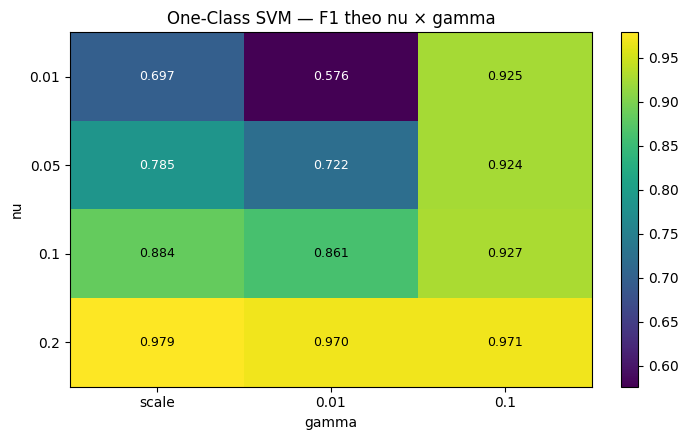

In [7]:
# One-Class SVM học một BIÊN BAO quanh vùng dữ liệu bình thường trong không
# gian kernel. Mẫu nằm ngoài biên bị coi là bất thường.
#
# nu là tham số then chốt, mang hai nghĩa cùng lúc: chặn trên tỷ lệ mẫu train
# bị coi là ngoại lai, và chặn dưới tỷ lệ mẫu train trở thành support vector.
# nu nhỏ → biên bao chặt quanh dữ liệu, ít báo động nhưng dễ bỏ sót;
# nu lớn → biên lỏng hơn, nhiều báo động hơn.
#
# Vì One-Class SVM đắt theo bình phương số mẫu, ta huấn luyện trên tập con
# Z_sub (xem phần cấu hình).
rows = []
t0 = time.perf_counter()
for nu in NU_GRID:
    for g in OCSVM_GAMMA:
        m = OneClassSVM(kernel="rbf", nu=nu, gamma=g).fit(Z_sub)
        yp = (m.predict(Z_te) == -1).astype(int)
        r = evaluate(y_te, yp, anomaly_score(m, Z_te), f"{nu}|{g}")
        r["nu"], r["gamma"] = nu, str(g)
        rows.append(r)
oc_time = time.perf_counter() - t0

oc_df = pd.DataFrame(rows)
print(f"Dò {len(rows)} cấu hình trên {Z_sub.shape[0]:,} mẫu "
      f"mất {oc_time:.1f} giây")
print()
print(oc_df.sort_values("f1", ascending=False)
      .head(5)[["nu", "gamma", "prec", "rec", "f1", "auc"]].round(4)
      .to_string(index=False))

bo = oc_df.loc[oc_df["f1"].idxmax()]
NU_BEST = float(bo["nu"])
G_BEST = bo["gamma"] if bo["gamma"] == "scale" else float(bo["gamma"])
print(f"\n→ Cấu hình tốt nhất: nu={NU_BEST:g}, gamma={bo['gamma']} "
      f"(F1 = {bo['f1']:.4f})")
print(OCSVM_COMMENT)

piv = oc_df.pivot(index="nu", columns="gamma", values="f1")
piv = piv[[str(g) for g in OCSVM_GAMMA]]
fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(piv.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(piv.columns)), piv.columns)
ax.set_yticks(range(len(piv.index)), [f"{v:g}" for v in piv.index])
ax.set_xlabel("gamma")
ax.set_ylabel("nu")
ax.set_title("One-Class SVM — F1 theo nu × gamma")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center",
                color="white" if v < piv.values.max() * .85 else "black",
                fontsize=9)
plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout()
plt.show()


### A5. Local Outlier Factor – Mật Độ Cục Bộ

Dò 5 giá trị n_neighbors mất 2.4 giây

               prec     rec      f1  f1_macro     auc
n_neighbors                                          
5            0.9706  0.3464  0.5106    0.3501  0.6579
10           0.9734  0.3568  0.5222    0.3580  0.6920
20           0.9546  0.2451  0.3901    0.2782  0.6203
35           0.9662  0.3929  0.5587    0.3760  0.7384
50           0.9671  0.5402  0.6932    0.4596  0.7951

→ n_neighbors tốt nhất: 50 (F1 = 0.6932)

Nhận xét: LOF cho kết quả kém hơn hẳn hai phương pháp kia (tốt nhất chỉ 0,69
ở k=50) và không đơn điệu theo k — ở k=20 còn tụt xuống 0,39. Nguyên nhân:
LOF so sánh mật độ CỤC BỘ, phù hợp khi bất thường nằm lẫn trong vùng dày đặc.
Ở đây mã độc tạo thành những cụm riêng khá lớn, nên xét theo mật độ cục bộ thì
các cụm đó trông cũng "dày" như cụm lành tính.
Bù lại, LOF chạy rất nhanh so với One-Class SVM.


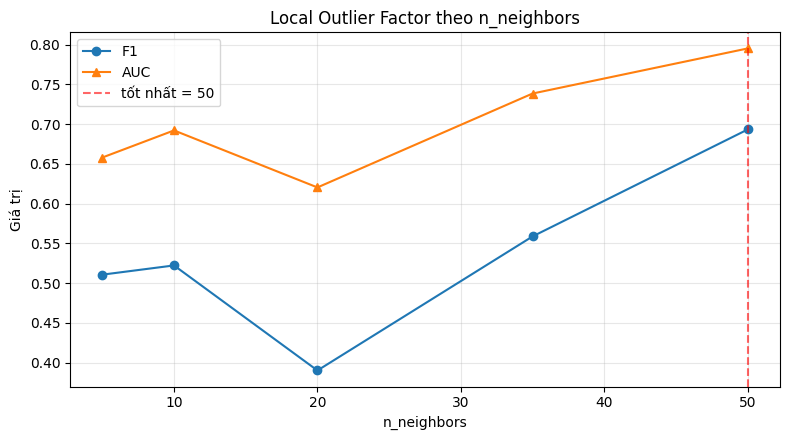

In [8]:
# Local Outlier Factor so sánh MẬT ĐỘ CỤC BỘ quanh một mẫu với mật độ quanh
# các láng giềng của nó. Nếu mẫu nằm ở vùng thưa hơn hẳn so với láng giềng
# thì nó bất thường. Khác với Isolation Forest (nhìn toàn cục), LOF bắt được
# bất thường cục bộ — mẫu nằm ở rìa một cụm dày.
#
# Tham số n_neighbors quyết định "cục bộ" rộng bao nhiêu. Phải đặt
# novelty=True mới dùng được để dự đoán trên dữ liệu mới.
rows = []
t0 = time.perf_counter()
for k in K_GRID:
    m = LocalOutlierFactor(n_neighbors=k, novelty=True).fit(Z_sub)
    yp = (m.predict(Z_te) == -1).astype(int)
    rows.append(evaluate(y_te, yp, anomaly_score(m, Z_te), k))
lof_time = time.perf_counter() - t0

lof_df = pd.DataFrame(rows).set_index("model").round(4)
lof_df.index.name = "n_neighbors"
print(f"Dò {len(K_GRID)} giá trị n_neighbors mất {lof_time:.1f} giây")
print()
print(lof_df[["prec", "rec", "f1", "f1_macro", "auc"]])

K_BEST = int(lof_df["f1"].idxmax())
print(f"\n→ n_neighbors tốt nhất: {K_BEST} (F1 = {lof_df.loc[K_BEST, 'f1']:.4f})")
print(LOF_COMMENT)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(lof_df.index, lof_df["f1"], marker="o", label="F1")
ax.plot(lof_df.index, lof_df["auc"], marker="^", label="AUC")
ax.axvline(K_BEST, color="red", ls="--", alpha=.6, label=f"tốt nhất = {K_BEST}")
ax.set_xlabel("n_neighbors")
ax.set_ylabel("Giá trị")
ax.set_title("Local Outlier Factor theo n_neighbors")
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


### A6. So Sánh Ba Phương Pháp (Kèm Mốc So Sánh Tầm Thường)

Tỷ lệ lớp dương trong tập test: 91.9%
MỐC TẦM THƯỜNG — gắn cờ mọi mẫu là malware: F1 = 0.9578 | F1-macro = 0.4789

                                 prec     rec      f1  f1_macro     auc
model                                                                  
Isolation Forest (phân vị 90)  0.9922  0.9138  0.9514    0.7929  0.9701
One-Class SVM (nu=0.2)         0.9836  0.9736  0.9786    0.8750  0.9525
Local Outlier Factor (k=50)    0.9671  0.5402  0.6932    0.4596  0.7951

   Isolation Forest (phân vị 90)      KHÔNG VƯỢT mốc tầm thường về F1
   One-Class SVM (nu=0.2)             VƯỢT mốc tầm thường về F1
   Local Outlier Factor (k=50)        KHÔNG VƯỢT mốc tầm thường về F1

── Trên tập test CÂN BẰNG (1,512 lành tính / 1,512 tấn công), mốc tầm thường F1 = 0.6667 ──
                        prec     rec      f1  f1_macro     auc
model                                                         
Isolation Forest      0.9192  0.9253  0.9222    0.9220  0.9715
One-Class SVM         0.8420  0.9795  

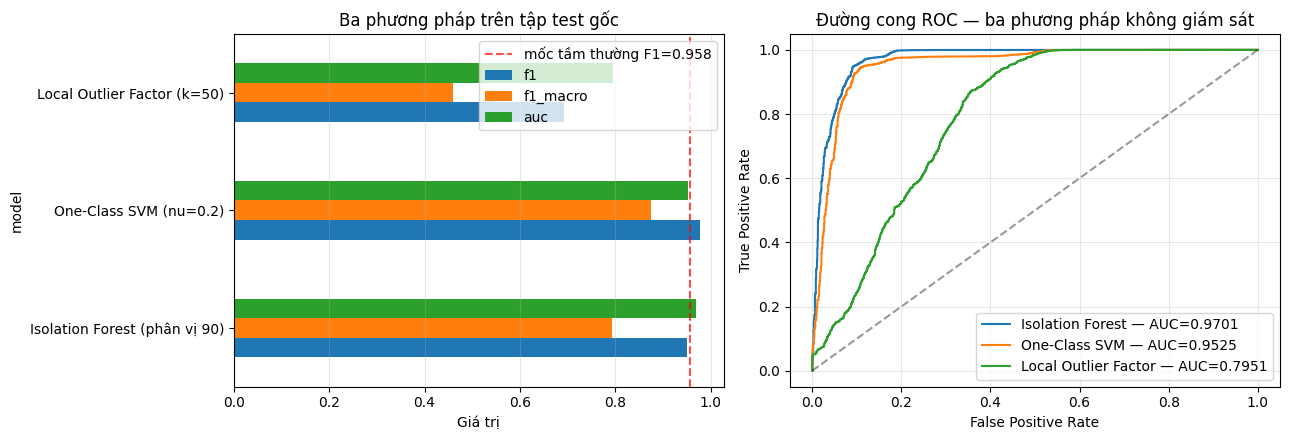

In [9]:
# So sánh ba phương pháp tại cấu hình tốt nhất của mỗi phương pháp.
#
# ⚠ TRƯỚC KHI ĐỌC CÁC CON SỐ: tập test của bài này gồm toàn bộ mẫu lành tính
# còn lại cộng với toàn bộ mẫu tấn công, nên tỷ lệ lớp dương có thể rất cao.
# Khi đó F1 bị thổi phồng: chỉ cần GẮN CỜ MỌI MẪU là tấn công đã đạt F1 rất
# cao mà không học được gì. Vì vậy ta in kèm:
#   (1) mốc so sánh tầm thường "gắn cờ tất cả";
#   (2) F1-macro — trung bình F1 của cả hai lớp, không bị lớp đa số chi phối;
#   (3) AUC — không phụ thuộc tỷ lệ lớp;
#   (4) kết quả trên một tập test CÂN BẰNG lấy mẫu lại.
iso_best = IsolationForest(n_estimators=N_TREES, contamination="auto",
                           random_state=SEED, n_jobs=-1).fit(Z_fit)
s_iso = anomaly_score(iso_best, Z_te)
yp_iso = (s_iso >= THR_ISO).astype(int)

oc_best = OneClassSVM(kernel="rbf", nu=NU_BEST, gamma=G_BEST).fit(Z_sub)
s_oc = anomaly_score(oc_best, Z_te)
yp_oc = (oc_best.predict(Z_te) == -1).astype(int)

lof_best = LocalOutlierFactor(n_neighbors=K_BEST, novelty=True).fit(Z_sub)
s_lof = anomaly_score(lof_best, Z_te)
yp_lof = (lof_best.predict(Z_te) == -1).astype(int)

rows = [
    evaluate(y_te, yp_iso, s_iso, f"Isolation Forest (phân vị {PCTL_BEST:g})"),
    evaluate(y_te, yp_oc, s_oc, f"One-Class SVM (nu={NU_BEST:g})"),
    evaluate(y_te, yp_lof, s_lof, f"Local Outlier Factor (k={K_BEST})"),
]
cmp_df = pd.DataFrame(rows).set_index("model").round(4)

ones = np.ones_like(y_te)
triv_f1 = f1_score(y_te, ones, zero_division=0)
triv_f1m = f1_score(y_te, ones, average="macro", zero_division=0)

print(f"Tỷ lệ lớp dương trong tập test: {y_te.mean()*100:.1f}%")
print(f"MỐC TẦM THƯỜNG — gắn cờ mọi mẫu là {TARGET_NAMES[1].lower()}: "
      f"F1 = {triv_f1:.4f} | F1-macro = {triv_f1m:.4f}")
print()
print(cmp_df[["prec", "rec", "f1", "f1_macro", "auc"]])
print()
for nm, v in cmp_df.iterrows():
    print(f"   {nm[:34]:34s} {'VƯỢT' if v['f1'] > triv_f1 else 'KHÔNG VƯỢT'} "
          f"mốc tầm thường về F1")

# ── Tập test cân bằng ──────────────────────────────────────────────────────
pos, neg = np.where(y_te == 1)[0], np.where(y_te == 0)[0]
if len(pos) > len(neg):
    pos = np.random.RandomState(SEED).choice(pos, size=len(neg), replace=False)
bal = np.sort(np.concatenate([pos, neg]))
y_b = y_te[bal]
rows_b = [
    evaluate(y_b, yp_iso[bal], s_iso[bal], "Isolation Forest"),
    evaluate(y_b, yp_oc[bal], s_oc[bal], "One-Class SVM"),
    evaluate(y_b, yp_lof[bal], s_lof[bal], "Local Outlier Factor"),
]
bal_df = pd.DataFrame(rows_b).set_index("model").round(4)
print(f"\n── Trên tập test CÂN BẰNG ({int((y_b==0).sum()):,} lành tính / "
      f"{int((y_b==1).sum()):,} tấn công), mốc tầm thường F1 = "
      f"{f1_score(y_b, np.ones_like(y_b), zero_division=0):.4f} ──")
print(bal_df[["prec", "rec", "f1", "f1_macro", "auc"]])
print(COMPARE_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cmp_df[["f1", "f1_macro", "auc"]].plot.barh(ax=axes[0])
axes[0].axvline(triv_f1, color="red", ls="--", alpha=.7,
                label=f"mốc tầm thường F1={triv_f1:.3f}")
axes[0].set_xlabel("Giá trị")
axes[0].set_title("Ba phương pháp trên tập test gốc")
axes[0].legend()
axes[0].grid(axis="x", alpha=.3)

for nm, sc in [("Isolation Forest", s_iso), ("One-Class SVM", s_oc),
               ("Local Outlier Factor", s_lof)]:
    fpr, tpr, _ = roc_curve(y_te, sc)
    axes[1].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_te, sc):.4f}")
axes[1].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Đường cong ROC — ba phương pháp không giám sát")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A7. Cái Giá Của Việc Không Dùng Nhãn Tấn Công

Random Forest được huấn luyện trên 15,534 mẫu CÓ NHÃN (trong đó 12,007 mẫu tấn công)
Phương pháp không giám sát chỉ dùng 3,527 mẫu lành tính, KHÔNG dùng một nhãn tấn công nào

                                                   prec     rec      f1  \
model                                                                     
Tốt nhất không giám sát: One-Class SVM (nu=0.2)  0.9836  0.9736  0.9786   
Random Forest CÓ giám sát                        0.9925  0.9973  0.9949   

                                                 f1_macro     auc  
model                                                              
Tốt nhất không giám sát: One-Class SVM (nu=0.2)    0.8750  0.9525  
Random Forest CÓ giám sát                          0.9886  0.9939  

Khoảng cách F1: +0.0163 | khoảng cách AUC: +0.0414

Nhận xét: Random Forest có giám sát đạt F1 0,9949 và AUC 0,9939, cao hơn
phương pháp không giám sát tốt nhất khoảng 0,016 F1 và 0,04 AUC. Khoảng cách
này nhỏ một cách đáng ngạc nhiên nếu xét rằng Ra

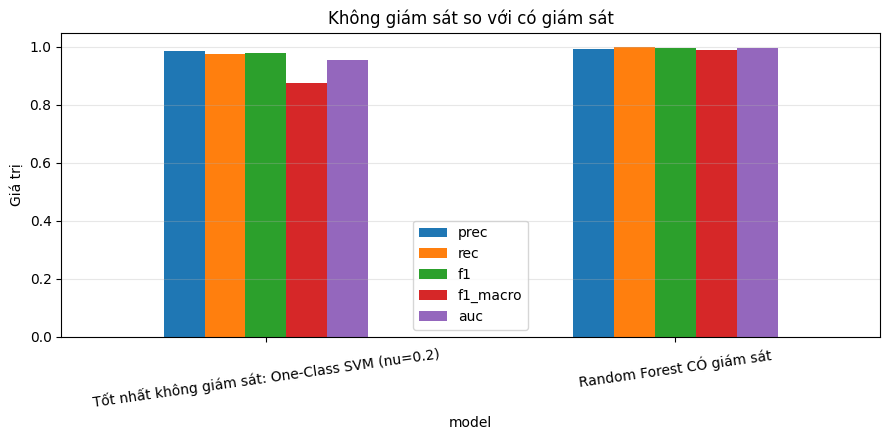

In [10]:
# Câu hỏi quan trọng: nếu ta CÓ nhãn tấn công thì mô hình tốt hơn bao nhiêu?
# Phần này huấn luyện một Random Forest có giám sát trên cùng dữ liệu nhưng
# được dùng cả nhãn tấn công, rồi so với phương pháp không giám sát tốt nhất.
#
# Đây là cách định lượng CÁI GIÁ của việc không có nhãn — con số này quyết
# định việc có nên đầu tư vào việc gán nhãn dữ liệu hay không.
X_a, X_b, y_a, y_b2 = train_test_split(X_sup, y_sup, test_size=TEST_SIZE,
                                       random_state=SEED, stratify=y_sup)
sc_sup = StandardScaler().fit(X_a)
rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf.fit(sc_sup.transform(X_a), y_a)
Zb = sc_sup.transform(X_b)
rf_res = evaluate(y_b2, rf.predict(Zb), rf.predict_proba(Zb)[:, 1],
                  "Random Forest CÓ giám sát")

best_unsup = cmp_df["f1"].idxmax()
print(f"Random Forest được huấn luyện trên {len(y_a):,} mẫu CÓ NHÃN "
      f"(trong đó {int(y_a.sum()):,} mẫu tấn công)")
print(f"Phương pháp không giám sát chỉ dùng {Z_fit.shape[0]:,} mẫu lành tính, "
      f"KHÔNG dùng một nhãn tấn công nào")
print()
gap = pd.DataFrame([
    dict(cmp_df.loc[best_unsup], model=f"Tốt nhất không giám sát: {best_unsup[:30]}"),
    rf_res,
]).set_index("model").round(4)
print(gap[["prec", "rec", "f1", "f1_macro", "auc"]])
print(f"\nKhoảng cách F1: {rf_res['f1'] - cmp_df.loc[best_unsup, 'f1']:+.4f} | "
      f"khoảng cách AUC: {rf_res['auc'] - cmp_df.loc[best_unsup, 'auc']:+.4f}")
print(SUPERVISED_COMMENT)

ax = gap[["prec", "rec", "f1", "f1_macro", "auc"]].plot.bar(figsize=(9, 4.5), rot=8)
ax.set_ylabel("Giá trị")
ax.set_title("Không giám sát so với có giám sát")
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


### A8. Năng Lực Phát Hiện Theo Từng Họ Mã Độc

                     số mẫu  tỷ lệ phát hiện  điểm bất thường TB
nhóm                                                            
ADWARE                 4069           0.9042              0.5623
RANSOMWARE             4586           0.9178              0.5637
SCAREWARE              5027           0.9131              0.5671
SMSMALWARE             3438           0.9209              0.5670
BENIGN (tham chiếu)    5039           0.0945              0.3888

Ghi chú: với nhóm BENIGN, 'tỷ lệ phát hiện' chính là tỷ lệ CẢNH BÁO GIẢ.

Nhận xét: tỷ lệ phát hiện khá ĐỒNG ĐỀU giữa bốn nhóm họ mã độc, dao động
trong khoảng 0,904 đến 0,921, trong khi tỷ lệ cảnh báo giả trên mẫu Benign chỉ
0,094. Đây là kết quả quan trọng nhất của bài:

Mô hình chưa từng nhìn thấy MỘT mẫu mã độc nào trong lúc huấn luyện, nhưng bắt
được khoảng 91% mẫu của cả bốn nhóm — kể cả những họ hoàn toàn khác nhau về
cách hoạt động (Adware hiển thị quảng cáo, Ransomware mã hóa dữ liệu, SMS
Malware gửi tin nhắn ngầm). Năng lực này 

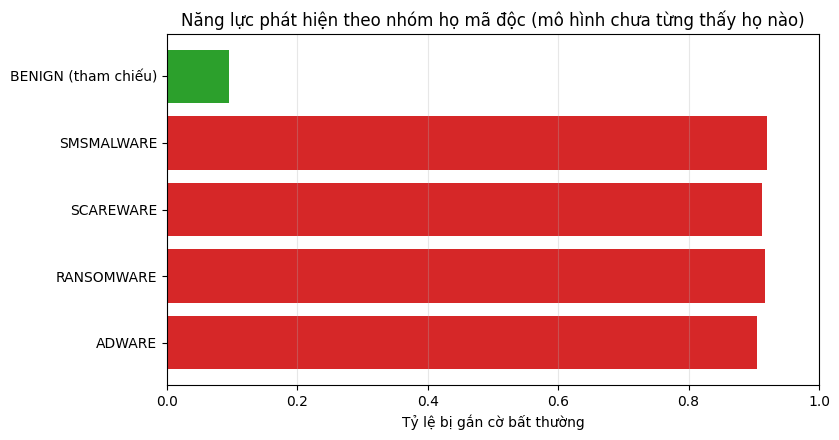

In [11]:
# Câu hỏi then chốt của phát hiện bất thường: mô hình có bắt được loại tấn
# công mà nó CHƯA TỪNG THẤY hay không? Vì tập train chỉ gồm mẫu lành tính,
# mọi họ mã độc đều là "chưa từng thấy" đối với mô hình.
#
# Ta tính tỷ lệ phát hiện riêng cho từng nhóm họ mã độc để xem năng lực phát
# hiện có đồng đều hay chỉ tốt với một vài họ.
rows = []
for g in ["ADWARE", "RANSOMWARE", "SCAREWARE", "SMSMALWARE"]:
    sel = np.array([str(f).startswith(g) for f in fam_all])
    if sel.sum() == 0:
        continue
    s = anomaly_score(iso_best, scaler.transform(X_all[sel]))
    rows.append({"nhóm": g, "số mẫu": int(sel.sum()),
                 "tỷ lệ phát hiện": float((s >= THR_ISO).mean()),
                 "điểm bất thường TB": float(s.mean())})
sel0 = (y_all == 0)
s0 = anomaly_score(iso_best, scaler.transform(X_all[sel0]))
rows.append({"nhóm": "BENIGN (tham chiếu)", "số mẫu": int(sel0.sum()),
             "tỷ lệ phát hiện": float((s0 >= THR_ISO).mean()),
             "điểm bất thường TB": float(s0.mean())})

fam_df = pd.DataFrame(rows).set_index("nhóm").round(4)
print(fam_df)
print(f"\nGhi chú: với nhóm BENIGN, 'tỷ lệ phát hiện' chính là tỷ lệ CẢNH BÁO "
      f"GIẢ.")
print(FAMILY_COMMENT)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
colors = ["tab:red"] * (len(fam_df) - 1) + ["tab:green"]
ax.barh(fam_df.index, fam_df["tỷ lệ phát hiện"], color=colors)
ax.set_xlabel("Tỷ lệ bị gắn cờ bất thường")
ax.set_title("Năng lực phát hiện theo nhóm họ mã độc (mô hình chưa từng thấy họ nào)")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


---
## Nhận Xét & Câu Hỏi Thảo Luận

**Tổng hợp những gì bài thực hành cho thấy**

1. `contamination` chỉ dịch ngưỡng chứ không thay đổi chất lượng xếp hạng — AUC đứng yên quanh 0,970 qua mọi giá trị.
2. Đặt ngưỡng theo phân vị điểm trên tập train gắn trực tiếp với ràng buộc vận hành: phân vị 95 nghĩa là chấp nhận khoảng 5% cảnh báo giả.
3. One-Class SVM cho F1 cao nhất (0,9786), Isolation Forest cho AUC cao nhất (0,9701), còn LOF thất bại (0,6932).
4. Tập test có 92% mẫu tấn công nên F1 bị thổi phồng: mốc tầm thường "gắn cờ tất cả" đã đạt 0,9578. Trên tập cân bằng, Isolation Forest (0,922) và OC-SVM (0,906) vượt xa mốc 0,667, còn LOF (0,590) thì kém hơn mốc.
5. Random Forest có giám sát chỉ hơn khoảng 0,016 F1 và 0,04 AUC, dù được dùng 12.007 nhãn tấn công.
6. Tỷ lệ phát hiện đồng đều 0,904–0,921 trên cả bốn nhóm họ mã độc, trong khi cảnh báo giả chỉ 0,094 — dù mô hình chưa từng thấy một mẫu mã độc nào.

**Câu hỏi thảo luận**

1. Vì sao AUC không thay đổi khi `contamination` thay đổi, trong khi F1 thay đổi rất mạnh? Hãy giải thích bằng cách phân biệt giữa "điểm bất thường" và "ngưỡng cắt".
2. Mốc tầm thường "gắn cờ mọi mẫu là tấn công" đạt F1 = 0,9578. Hãy tính tay con số đó từ tỷ lệ lớp dương 91,9% và giải thích vì sao F1 lại cao như vậy dù mô hình không học gì.
3. Trên tập test gốc, OC-SVM có F1 cao hơn Isolation Forest; trên tập cân bằng thì ngược lại. Hãy giải thích và cho biết nên tin kết quả nào.
4. LOF kém hơn hẳn hai phương pháp kia và tốt nhất ở `k=50`. Dựa trên cách LOF so sánh mật độ cục bộ, hãy giải thích vì sao cấu trúc dữ liệu mã độc ở đây lại không phù hợp với nó.
5. Khoảng cách giữa không giám sát và có giám sát chỉ khoảng 0,04 AUC. Trong tình huống nào bạn vẫn sẽ chọn phương pháp không giám sát dù nó kém hơn một chút?
6. Phần A8 cho thấy mô hình bắt được khoảng 91% mẫu của cả bốn nhóm họ mã độc mà chưa từng thấy họ nào. Hãy giải thích vì sao mô hình có giám sát không bảo đảm được năng lực này.
7. Hãy đề xuất một kiến trúc IDS kết hợp cả hai: mô hình có giám sát cho tấn công đã biết và phát hiện bất thường cho tấn công chưa biết. Nêu rõ cách hợp nhất hai luồng cảnh báo.
